In [1]:
import h5py
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
import matplotlib.cm as cm
import numpy as np
import seaborn as sns
import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils
from datetime import datetime, timezone
# from scipy.optimize import curve_fit
# from scipy.signal import savgol_filter
# from scipy.ndimage import binary_dilation
from scipy.signal import find_peaks

from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

from MPG_HDF5_libs import *

In [2]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

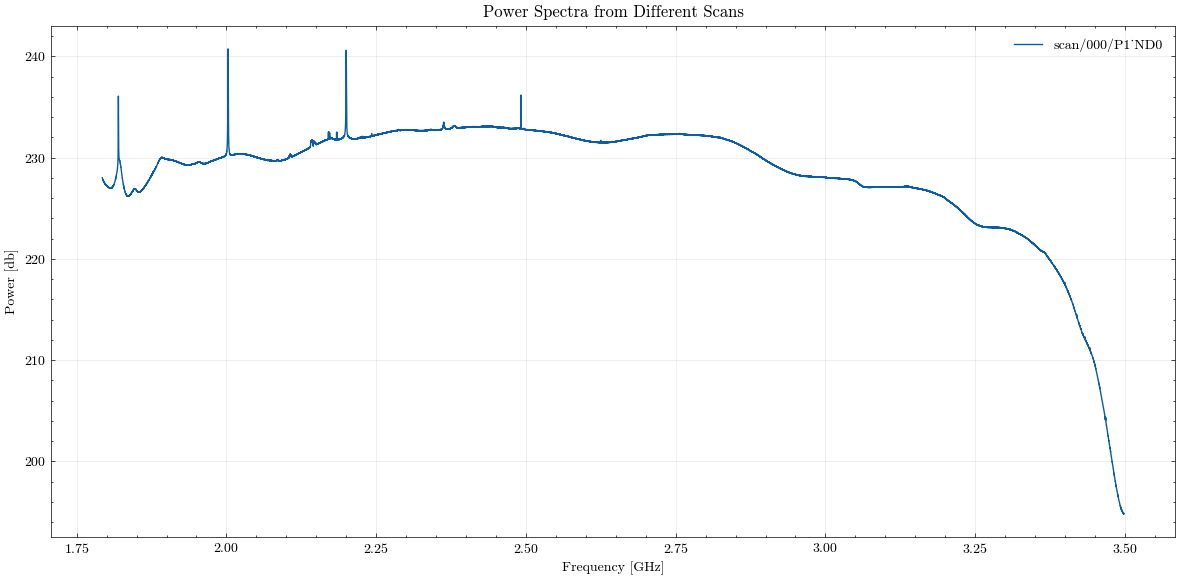

In [3]:
# Select different group os data

groups = [
    "scan/000/P1_ND0",
    # "scan/000/P1_ND1",
    # "scan/001/P0_ND0",
    # "scan/001/P0_ND1",
    # "scan/001/P1_ND0",
    # "scan/001/P1_ND1"
]


# plot the power spectrum
with h5py.File(filename,'r') as f:
    for g in groups:
        freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
        spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
        time = f[f"{g}/timestamp"][30:,0]
         
        # Average over time axis
        mean_spectrum = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

        # Plot
        plt.figure(figsize=(12,6))
        plt.plot(freq, mean_spectrum, label=g)

        plt.xlabel("Frequency [GHz]")
        plt.ylabel("Power [db]")
        plt.title("Power Spectra from Different Scans")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [4]:
# Baseline correction

def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method:Asymmetric Least Square

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    the signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline



Detected peak > 1σ are frequencies (GHz): ['1.8196', '2.0028', '2.1421', '2.1703', '2.1707', '2.1723', '2.1841', '2.1845', '2.1999', '2.3627', '2.4920']
Detected peak > 3σ are frequencies (GHz): ['1.8196', '2.0028', '2.1999', '2.4920']


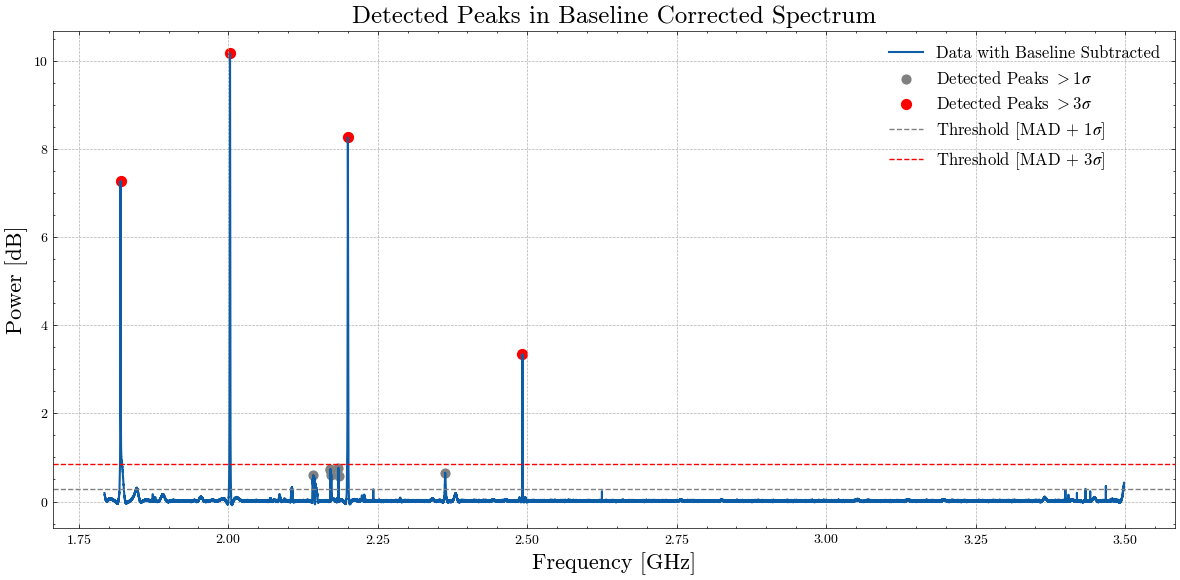

In [5]:
# Base line corrected and peaks detection
for g in groups:

    power_base_core = base_correction(freq, mean_spectrum)

        
    # Find peaks above 1 sigma from the MAD
    peaks, propreties = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + np.std(power_base_core),
                                distance=10,
                                prominence=0.5
                                )
    # Find peaks above 3 sigma from the MAD
    peaks1, propreties1 = find_peaks(power_base_core, 
                                height=MAD(power_base_core) + 3*np.std(power_base_core),
                                distance=10,
                                prominence=0.5
                                )

    plt.figure(figsize=(12, 6))

    # --- Plot baseline-corrected spectrum ---
    plt.plot(freq, power_base_core, label=f'Data with Baseline Subtracted', lw=1.5)

    # --- Plot detected peaks ---
    plt.scatter(freq[peaks], power_base_core[peaks], 
                color='gray', s=40, label='Detected Peaks $> 1σ$')

    plt.scatter(freq[peaks1], power_base_core[peaks1], 
                color='red', s=50, label='Detected Peaks $> 3σ$')

    # --- Plot threshold lines ---
    plt.axhline(y=MAD(power_base_core) + np.std(power_base_core), 
                color='gray', linestyle='--', label='Threshold [MAD + 1$σ$]')

    plt.axhline(y=MAD(power_base_core) + 3*np.std(power_base_core), 
            color='red', linestyle='--', label='Threshold [MAD + 3$σ$]')

    # --- Labels and formatting ---
    plt.xlabel("Frequency [GHz]",fontsize=16)
    plt.ylabel("Power [dB]",fontsize=16)
    plt.title("Detected Peaks in Baseline Corrected Spectrum", fontsize=18)
    plt.grid(True, linestyle='--')
    plt.legend(fontsize=12)
    plt.tight_layout()

   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.png', dpi=300)
   #plt.savefig(f'/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/Detected_Peaks_base_cor.pdf', dpi=300)


    # --- Print detected peak frequencies ---
    formatted_freqs = [f"{f:.4f}" for f in freq[peaks]]
    formatted_freqs1 = [f"{f:.4f}" for f in freq[peaks1]]

    print(f"Detected peak > 1σ are frequencies (GHz): {formatted_freqs}")
    print(f"Detected peak > 3σ are frequencies (GHz): {formatted_freqs1}")



In [6]:

# Define a function to quantify the RFI width
def quantify_RFI_width(freq, power, ax=None):
    """
    Quantify how wide an RFI peak is in frequency.

    Parameters:
    freq : array
        Frequency array.
    power : array
        Power array with baseline corrected.
    mask : boolean array
        Mask to select the frequency window of interest.

    Returns:
    start_freq : float
        Frequency where power rises above threshold.
    end_freq : float
        Frequency where power falls below threshold.
    peak_freq : float
        Frequency of the peak power.
    peak_power : float
        Value of the peak power.
    """


    # --- 1) Find where power rises above zero ---
    threshold = 0.05  # small threshold 
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) > 0:
        start_index = above_threshold[0]
        end_index = above_threshold[-1]
        start_freq = freq[start_index]
        end_freq = freq[end_index]
    else:
        start_freq = end_freq = np.nan
        print("No significant power detected in the masked range.")

    # --- 2) Find the frequency of the peak ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]


    print(f"=== Start Frequency: {start_freq:.4f} GHz ===")
    print(f"=== End Frequency: {end_freq:.4f} GHz ===")
    print(f"=== Peak Frequency: {peak_freq:.4f} GHz with Power: {peak_power:.4f} dB ===")
    


    # Number of channels corrupted.
    delta_frequency = (freq[1] - freq[0])  # spectral resolution / channel width
    chans = ((end_freq - start_freq) / delta_frequency)


    print(f'=== Number off corrupted channels: {chans: .1f} ===')
    print(f'=== Bandwidth of corrupeted frequency: {(end_freq-start_freq)*1e3:.1f} MHz ===')



    # --- Plot results ---

    if ax is None:
        fig,ax = plt.subplots(figsize=(12,6))

    ax.plot(freq, power, '.', color='steelblue', label='Data')
    ax.axvline(start_freq, color='green', linestyle='--', label='Start')
    ax.axvline(peak_freq, color='red', linestyle='-', label='Peak')
    ax.axvline(end_freq, color='orange', linestyle='--', label='End')
    ax.set_xlabel('Frequency [GHz]', fontsize=16)
    ax.set_ylabel('Power [dB]', fontsize=16)
    ax.legend(fontsize=14)
    ax.grid(linestyle='--')

    return start_freq, end_freq, peak_freq, peak_power


#--------------------------------------------#
#
#
#
#--------------------------------------------#


# Waterfall plot function for specified frequency range
def waterfall_timevsfreq(time, freq, spectrum, freq_mask, ax=None):
    """
    Generate a waterfall plot of power vs time and frequency.

    Parameters:
    time : array
        Time array in seconds since epoch.
    freq : array
        Frequency array in GHz.
    spectrum : 2D array
        Power spectrum with shape (time, frequency).
    freq_mask : boolean array
        Mask to select the frequency range of interest.
   ax : matplotlib.axes.Axes, optional
        Axis on which to draw the plot. If None, creates a new one.

    Returns:
    ax : matplotlib.axes.Axes
        The axis with the plotted data.
    """

    # --- Convert Power Spectrum to dB ---
    spectrum_db = 10 * np.log10(spectrum**2 + 1e-12)

    # Select the desired frequency channels
    power_channel = spectrum_db[:, freq_mask]

    # --- Convert Time to UTC Datetime ---
    time_utc = pd.to_datetime(time, unit="s", utc=True)

    # --- Select Frequency Range (GHz) ---
    freq_sel = freq[freq_mask]

    # --- Plot Waterfall (Frequency on x, Time on y) ---

    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 6))

    # --- Create Waterfall ---
    im = ax.imshow(
        power_channel,
        aspect='auto',
        origin='lower',
        extent=[freq_sel.min(), freq_sel.max(), 0, len(time_utc)],
        cmap='viridis'
    )

    # --- Colorbar ---

    cbar = plt.colorbar(im, ax=ax, label='Power [dB]')
    cbar.ax.tick_params(labelsize=14)       # set tick label size
    cbar.set_label('Power [dB]', fontsize=16)  # set label font size
    
    ax.set_xlabel('Frequency [GHz]', fontsize=16)
    ax.set_ylabel('Time [UTC]', fontsize=16)
    #plt.title('Waterfall Plot: Time vs Frequency', fontsize=18)

    # --- Y-axis: Time Ticks (UTC) ---
    n_ticks = 10
    tick_positions = np.linspace(0, len(time_utc) - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]
    ax.set_yticks(tick_positions)
    ax.set_yticklabels(tick_labels)

    # --- X-axis: Frequency ---
    ax.set_xlim(freq_sel.min(), freq_sel.max())
    ax.grid(False)




#--------------------------------------------#
#                                            #
#                                            #
#                                            #
#--------------------------------------------#




# Gaussian Fitting

def gaussian_fit_RFI (frequency, power, tie, ax=None):
    """ 
    The function, fittis a gaussian function to a frequency window

    Entries
    --------
    frequency: array
    power: array
    freq_min, freq_mac: frequency window
    tie: bolean - fit one or to gaussian 
        
    """

    # --- Initial Guess ---
    peak_idx = np.argmax(power)
    peak_amplitude = power[peak_idx]
    peak_frequency = frequency[peak_idx]

    # Estimate standard deviation for narrow gaussian
    delta_frequency = (frequency[1] - frequency[0])  # chanel width
    sigma_narrow = 5 * delta_frequency


    # Estimate sigma for broad band 
    median_amplitude = np.median(power)
    sigma_broad = 0.01
    amp_broad = (peak_amplitude - median_amplitude) / 5 


    # create a gaussian model for each 
    g_narrow = models.Gaussian1D(amplitude=peak_amplitude, mean=peak_frequency, stddev=sigma_narrow)
    g_broad  = models.Gaussian1D(amplitude=amp_broad, mean=peak_frequency, stddev=sigma_broad)


    if tie==True:
        # Tie the broad with the narrow
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means

        # combine them
        model_init = g_narrow + g_broad

        # Fitt the model
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(model_init, frequency, power)


        # Calculate the fwhm
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_0.value
        fwhm = 2.355 * sigma
        print(f'\n=== Bandwidth: {fwhm*1e6} kHz ===')
        my_label = '2 Gaussian Fit'
    
    else:
        # -- Fit the Gaussian ---
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(g_narrow,frequency,power)

        # Extrat fit parameters
        sigma = fitted_model.stddev.value
        fwhm = 2.355 * sigma
        print(f'\n=== Bandwidth: {fwhm*1e6} kHz ===')
        my_label = 'Gaussian Fit'

    


    if ax is None:
        fig, ax = plt.subplots(figsize=(12,6))
    ax.plot(frequency, power, '.', label="Data")
    ax.plot(frequency, fitted_model(frequency), 'r-', label=my_label)
    ax.set_xlabel("Frequency [GHz]", fontsize=16)
    ax.set_ylabel("Power [db]", fontsize=16)
    ax.legend(fontsize=14)
    ax.grid(True, alpha=0.3)



=== Start Frequency: 2.0003 GHz ===
=== End Frequency: 2.0048 GHz ===
=== Peak Frequency: 2.0028 GHz with Power: 10.1646 dB ===
=== Number off corrupted channels:  169.0 ===
=== Bandwidth of corrupeted frequency: 4.5 MHz ===

=== Bandwidth: 995.8492453635696 kHz ===


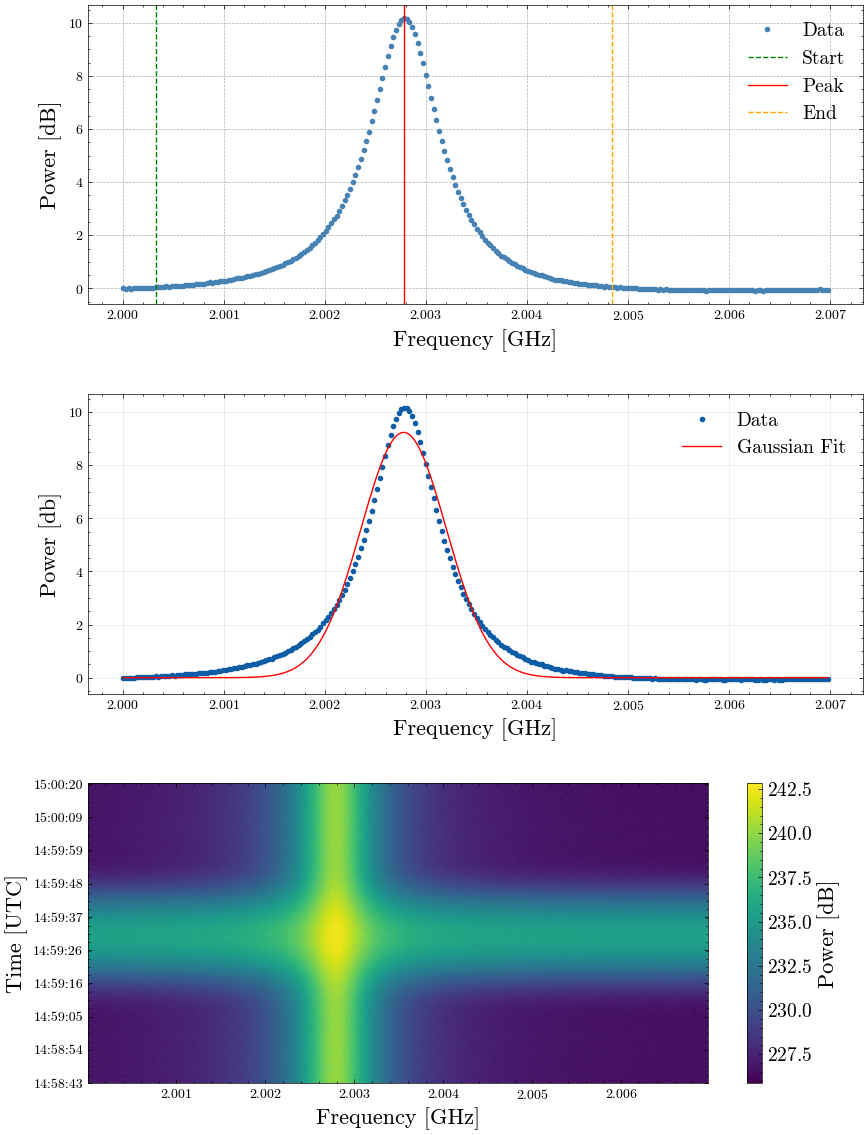

In [7]:
mask = (freq > 2.00) & (freq < 2.007)


fig, ax = plt.subplots(3,1, figsize=(10, 14))
plt.subplots_adjust(hspace=0.3,)

quantify_RFI_width(freq[mask], power_base_core[mask], ax=ax[0])
gaussian_fit_RFI(freq[mask], power_base_core[mask], tie=False,ax=ax[1] )
waterfall_timevsfreq(time, freq, spectrum, mask, ax=ax[2])

plt.show()

In [8]:
# Characterise the RFI

def characterize_RFI_width(freq, power, tie=False, ax=None, threshold=0.05):
    """
    Characterize the frequency width and fit of an RFI peak.

    Parameters
    ----------
    freq : array-like
        Frequency values [GHz].
    power : array-like
        Baseline-corrected power spectrum (linear or dB).
    tie : bool, optional
        If True, fits two tied Gaussians (narrow + broad). 
        If False, fits a single Gaussian. Default = False.
    ax : matplotlib.axes.Axes, optional
        Existing matplotlib axis for plotting.
    threshold : float, optional
        Power threshold to define start/end of RFI. Default = 0.05.

    Returns
    -------
    results : dict
        Dictionary containing:
        - start_freq [GHz]
        - end_freq [GHz]
        - peak_freq [GHz]
        - peak_power
        - n_channels
        - bandwidth [MHz]
        - fwhm [kHz]
        - fitted_model (Astropy model)
    """

    # --- 1. Identify the RFI region above threshold ---
    above_threshold = np.where(power > threshold)[0]

    if len(above_threshold) == 0:
        print(" No significant RFI detected above threshold.")
        return None

    start_index, end_index = above_threshold[0], above_threshold[-1]
    start_freq = freq[start_index]
    end_freq = freq[end_index]

    # --- 2 Find peak position and amplitude ---
    peak_index = np.argmax(power)
    peak_freq = freq[peak_index]
    peak_power = power[peak_index]

    # --- 3 Basic RFI statistics ---
    delta_f = np.mean(np.diff(freq))  # spectral resolution
    n_channels = (end_freq - start_freq) / delta_f
    bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz

    print(f"Start Frequency  : {start_freq:.6f} GHz")
    print(f"End Frequency    : {end_freq:.6f} GHz")
    print(f"Peak Frequency   : {peak_freq:.6f} GHz  | Power = {peak_power:.3f} dB")
    print(f"Corrupted Channels: {n_channels:.1f}")
    print(f"Corrupted Bandwidth         : {bandwidth:.2f} MHz")

    # --- 4 Build initial Gaussian models ---
    amp_narrow = peak_power
    sigma_narrow = 5 * delta_f  # narrow Gaussian width guess

    amp_broad = amp_narrow / 5
    sigma_broad = 0.01  # GHz-scale broad Gaussian

    g_narrow = models.Gaussian1D(amplitude=amp_narrow, mean=peak_freq, stddev=sigma_narrow)
    g_broad = models.Gaussian1D(amplitude=amp_broad, mean=peak_freq, stddev=sigma_broad)

    # --- 5 Model fitting ---
    fitter = fitting.LMLSQFitter()

    if tie:
        # Tie both Gaussian centers
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means
        model_init = g_narrow + g_broad
        fitted_model = fitter(model_init, freq, power)
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_1.value
        label = "2-Gaussian Fit (tied)"
    else:
        fitted_model = fitter(g_narrow, freq, power)
        sigma = fitted_model.stddev.value
        label = "Single Gaussian Fit"

    fwhm = 2.355 * sigma  # convert σ → FWHM
    print(f"Gaussian FWHM    : {fwhm * 1e6:.2f} kHz")
    print(f"Number of Channels at FWHM: {np.ceil(fwhm/delta_f)}")

    # --- 6 Plotting ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(freq, power, '.', color='steelblue', label='Data')
    ax.plot(freq, fitted_model(freq), 'black', lw=1, label=label)

    # Mark important frequencies
    ax.axvline(start_freq, color='green', ls='--', label='Start Peak')
    ax.axvline(peak_freq, color='red', ls='-', label='Peak')
    ax.axvline(end_freq, color='orange', ls='--', label='End Peak')

    ax.set_xlabel("Frequency [GHz]", fontsize=13)
    ax.set_ylabel("Power [dB]", fontsize=13)
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)

    plt.tight_layout()

    # --- 7️Return results ---
    return {
        "start_freq": start_freq,
        "end_freq": end_freq,
        "peak_freq": peak_freq,
        "peak_power": peak_power,
        "n_channels": n_channels,
        "bandwidth_MHz": bandwidth,
        "fwhm_kHz": fwhm * 1e6,
        "fitted_model": fitted_model,
    }


#--------------------------------------------#
#
#
#
#--------------------------------------------#




def ridgeplot_rfi_characterization1(time_utc, frequency, spectrum, mask=None, n_samples=10, threshold=0.05, ax=None):
    """
    Create a ridge plot of spectra vs frequency and characterize RFI features
    at selected time steps.
    """
    # --- Apply mask if provided ---
    if mask is not None:
        freq = frequency[mask]
        spec = spectrum[:, mask]
    else:
        freq = frequency
        spec = spectrum

    n_time = spec.shape[0]
    idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

    # Compute mean power per spectrum for colormap
    mean_power = [10 * np.log10(np.nanmean(spec[k, :]**2)) for k in idx]
    norm = plt.Normalize(min(mean_power), max(mean_power))
    colors = cm.plasma(norm(mean_power))

    # --- Create Figure ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))

    print("\n === RFI CHARACTERIZATION PER TIME STEP ===")
    print(f"Using threshold: {threshold:.3f}\n")

    for i, (k, color) in enumerate(zip(idx, colors)):
        y = spec[k, :]
        y_db = 10 * np.log10(y**2 + 1e-12)  # Convert to dB, avoid log(0)
        y_norm = (y_db - np.nanmean(y_db)) / np.nanstd(y_db)
        offset = i * 2.0

        # --- Plot ridge ---
        ax.plot(freq, y_norm + offset, color=color, lw=1.2)
        ax.fill_between(freq, offset, y_norm + offset, color=color, alpha=0.4)

        # --- RFI characterization ---
        above_threshold = np.where(y_db > threshold)[0]
        if len(above_threshold) > 0:
            start_index, end_index = above_threshold[0], above_threshold[-1]
            start_freq = freq[start_index]
            end_freq = freq[end_index]
            peak_index = np.argmax(y_db)
            peak_freq = freq[peak_index]
            peak_power = y_db[peak_index]

            delta_f = np.mean(np.diff(freq))  # channel width
            n_channels = (end_freq - start_freq) / delta_f
            bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz

            print(f"[{time_utc[k].strftime('%H:%M:%S')}]  "
                  f"Peak: {peak_freq:.6f} GHz | Power: {peak_power:.3f} dB | "
                  f"BW: {bandwidth:.2f} MHz | Channels: {n_channels:.1f}")
        else:
            print(f"[{time_utc[k].strftime('%H:%M:%S')}]  No RFI detected above threshold.")

    # colorbar to interoret variation
    sm=cm.ScalarMappable(cmap=cm.plasma, norm=norm)
    sm.set_array([])
    cbar=plt.colorbar(sm,ax=ax, label='Mean Power ')

    # --- Y-axis: Time Labels (UTC) ---
    n_ticks = min(10, n_samples)
    tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[idx[i]].strftime("%H:%M:%S") for i in tick_positions]

    ax.set_yticks(tick_positions * 2.0)
    ax.set_yticklabels(tick_labels, fontsize=9)
    ax.set_ylabel("Time [UTC]", fontsize=11)

    # --- X-axis ---
    ax.set_xlabel("Frequency [GHz]", fontsize=11)
    ax.set_title("RFI variation over the Observation", fontsize=13)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


Start Frequency  : 2.000326 GHz
End Frequency    : 2.004839 GHz
Peak Frequency   : 2.002783 GHz  | Power = 10.165 dB
Corrupted Channels: 169.0
Corrupted Bandwidth         : 4.51 MHz
Gaussian FWHM    : 995.85 kHz
Number of Channels at FWHM: 38.0

--- Summary ---
start_freq: 2.000326156616211
end_freq: 2.0048389434814453
peak_freq: 2.0027828216552734
peak_power: 10.164566040039062
n_channels: 169.0
bandwidth_MHz: 4.512786865234375
fwhm_kHz: 995.8492453635696
fitted_model: Model: Gaussian1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude            mean               stddev        
    ----------------- ----------------- ----------------------
    9.237534364217575 2.002779117255445 0.00042286592159811875


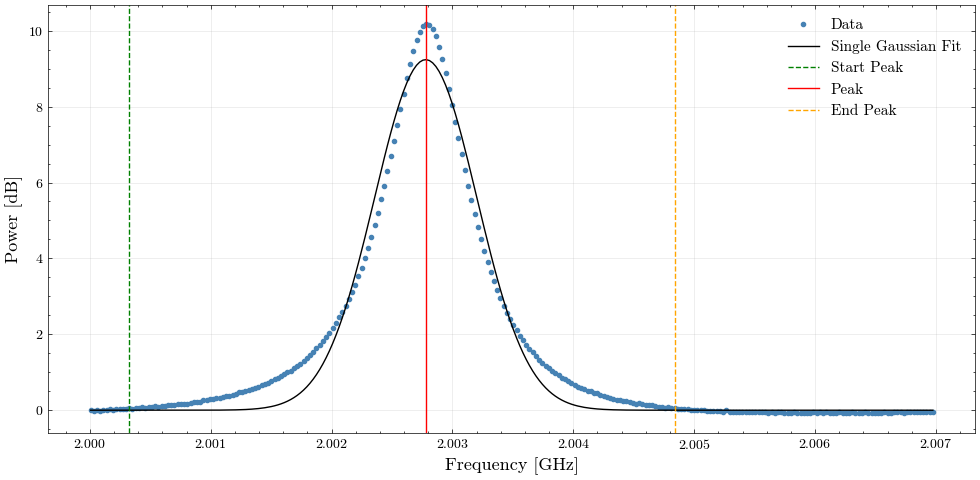

In [9]:
results = characterize_RFI_width(freq[mask], power_base_core[mask], tie=False)

print("\n--- Summary ---")
for k, v in results.items():
    print(f"{k}: {v}")


# Creat a ridge plot for different time step.

In [10]:
time_utc = pd.to_datetime(time, unit="s", utc=True)


# Convert to DataFrame (choose a subset if data is large)
n_samples = 10  # number of time steps to plot
idx = np.linspace(0, spectrum.shape[0]-1, n_samples, dtype=int)

offset = 0.08 # vertical offset between ridges

df = pd.DataFrame({
    "Frequency (GHz)": np.asarray(np.tile(freq, n_samples), dtype=float).ravel(),
    "Power (dB)": np.asarray(spectrum[idx, :].flatten(), dtype=float),
    "Time Step": np.repeat(np.arange(n_samples), len(freq))
})


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)


<Figure size 1000x800 with 0 Axes>

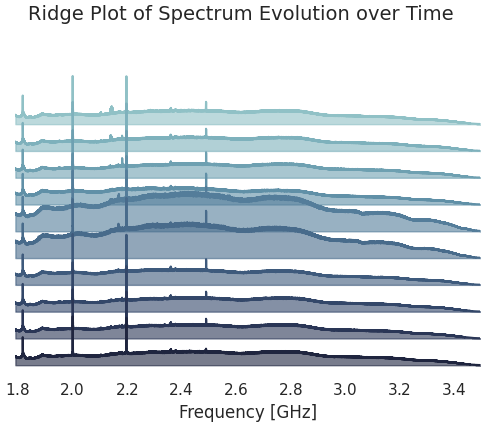

In [11]:

plt.figure(figsize=(10, 8))

sns.set(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

# Sort time steps for nice stacking order
time_order = sorted(df["Time Step"].unique())

# Ridge plot
pal = sns.cubehelix_palette(len(time_order), rot=-.25, light=.7)

g = sns.FacetGrid(df, row="Time Step", hue="Time Step", aspect=15, height=0.4, palette=pal)

# Draw each spectrum
g.map_dataframe(sns.lineplot, x="Frequency (GHz)", y="Power (dB)")

# Fill area under each curve for a smooth ridge effect
from matplotlib import pyplot as plt
from matplotlib.patches import Polygon

for ax, (_, subdf) in zip(g.axes.flat, df.groupby("Time Step")):
    ax.fill_between(subdf["Frequency (GHz)"], subdf["Power (dB)"], color=pal[subdf["Time Step"].iloc[0]], alpha=0.6)
    ax.set_xlim(freq.min(), freq.max())
    ax.set_yticks([])

# Style adjustments
g.figure.subplots_adjust(hspace=-0.6)
g.set_titles("")
g.set(yticks=[], ylabel="")
g.despine(bottom=True, left=True)

plt.xlabel("Frequency [GHz]")
plt.suptitle("Ridge Plot of Spectrum Evolution over Time", fontsize=14, y=1.02)
plt.show()


In [12]:
time_utc

DatetimeIndex(['2023-03-11 14:58:43.686180592+00:00',
               '2023-03-11 14:58:43.839572191+00:00',
               '2023-03-11 14:58:43.992964029+00:00',
               '2023-03-11 14:58:44.146355629+00:00',
               '2023-03-11 14:58:44.299747229+00:00',
               '2023-03-11 14:58:44.453139067+00:00',
               '2023-03-11 14:58:44.606530666+00:00',
               '2023-03-11 14:58:44.759922504+00:00',
               '2023-03-11 14:58:44.913314104+00:00',
               '2023-03-11 14:58:45.066705704+00:00',
               ...
               '2023-03-11 15:00:19.402594566+00:00',
               '2023-03-11 15:00:19.555986404+00:00',
               '2023-03-11 15:00:19.709378004+00:00',
               '2023-03-11 15:00:19.862769604+00:00',
               '2023-03-11 15:00:20.016161442+00:00',
               '2023-03-11 15:00:20.169553041+00:00',
               '2023-03-11 15:00:20.322944641+00:00',
               '2023-03-11 15:00:20.476336479+00:00',
         

In [13]:

# # Example arrays (replace with your real ones)
# # freq: shape (63877,)
# # spectrum: shape (634, 63877)


# freq = freq[mask]
# spectrum = spectrum[:,mask]

# n_time = spectrum.shape[0]
# n_freq = spectrum.shape[1]

# # --- Select evenly spaced time indices for plotting ---
# n_samples = 10   # number of ridges to display
# idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

# # --- Create figure ---
# plt.figure(figsize=(10, 8))

# offset = np.nanmax(spectrum) * 3  # vertical offset between curves

# for i, k in enumerate(idx):
#     y = spectrum[k, :]

#     # Normalize each spectrum (optional, for better comparison)
#     y_norm = (y - np.nanmean(y)) / np.nanstd(y)

#     # Offset and plot
#     plt.plot(freq, y_norm + i, color="C0", lw=1.0)
#     plt.fill_between(freq, i, y_norm + i, alpha=0.4, color="C0")

# # --- Aesthetics ---
# plt.xlabel("Frequency [GHz]")
# plt.ylabel("Relative Power + Offset")
# plt.title("Ridge Plot of Spectra Over Time")
# plt.yticks([])
# plt.grid(alpha=0.2)

# # Label each ridge with its time step
# for i, k in enumerate(idx):
#     plt.text(freq[0], i, f"t={k}", va='center', fontsize=8, color='black')

# plt.tight_layout()
# plt.show()


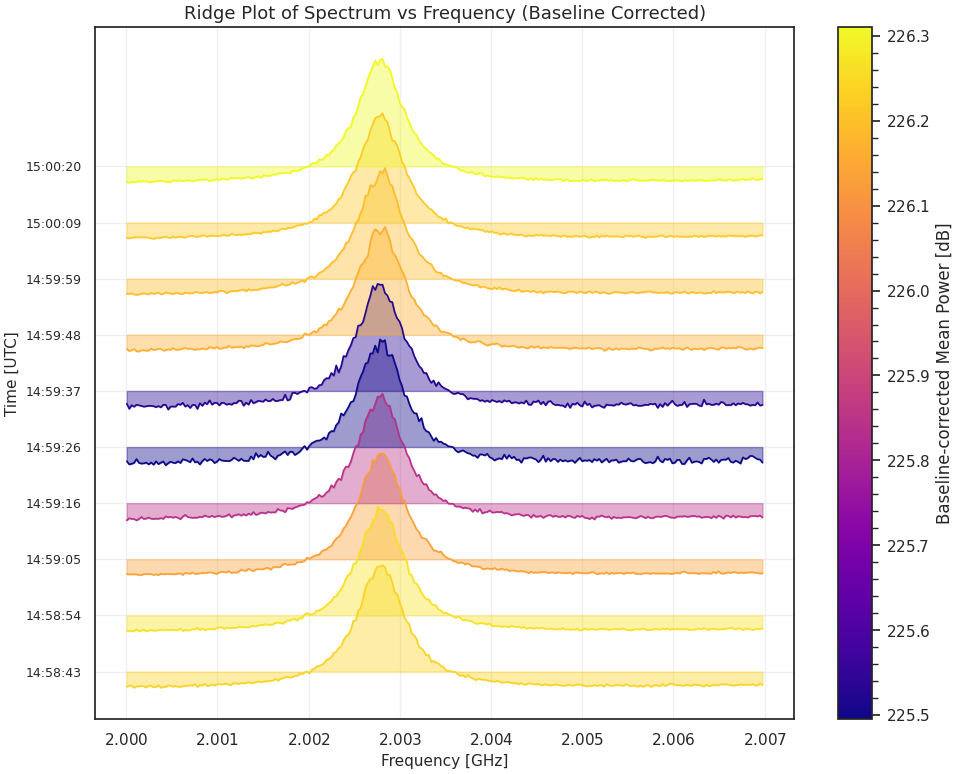

In [14]:
# --- Extract subset ---
frequency = freq[mask]
spec = spectrum[:, mask]

n_time, n_freq = spec.shape

# --- Configuration ---
n_samples = 10  # number of ridges to show
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

# --- Compute detrended (baseline-corrected) power for color normalization ---
det_power = []
mean_spectra = []

for k in idx:
    # Average spectrum at selected time
    mean_spectrum = spec[k, :]
    
    # --- Apply baseline correction ---
    corrected_spectrum = base_correction(frequency, mean_spectrum)
    mean_spectra.append(corrected_spectrum)
    
    # Compute power in dB after correction
    pwr = 10 * np.log10(np.nanmean(corrected_spectrum**2))
    det_power.append(pwr)

# --- Normalize color map according to corrected power ---
norm = plt.Normalize(vmin=np.min(det_power), vmax=np.max(det_power))
colors = cm.plasma(norm(det_power))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(10, 8))

for i, (y, color) in enumerate(zip(mean_spectra, colors)):
    # Normalize each corrected spectrum for ridge shape visualization
    y_norm = (y - np.nanmean(y)) / np.nanstd(y)
    
    # Vertical offset per ridge
    offset = i * 2.0
    
    # --- Plot ridge ---
    ax.plot(frequency, y_norm + offset, color=color, lw=1.2)
    ax.fill_between(frequency, offset, y_norm + offset, color=color, alpha=0.4)

# --- Colorbar for power interpretation ---
sm = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Baseline-corrected Mean Power [dB]')

# --- Y-axis: Time labels (UTC) ---
n_ticks = min(10, n_samples)
tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
tick_labels = [time_utc[idx[i]].strftime("%H:%M:%S") for i in tick_positions]

ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)

# --- X-axis and aesthetics ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
ax.set_title("Ridge Plot of Spectrum vs Frequency (Baseline Corrected)", fontsize=13)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [15]:
# # plot the power spectrum
# with h5py.File(filename,'r') as f:
#     for g in groups:
#         freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
#         spectrum = f[f"{g}/spectrum"][30:,1600:-60]        # (time × freq)
#         time = f[f"{g}/timestamp"][30:,0]
        


#         # frequency = freq[mask]
#         # spec = spectrum[:,mask]

#         n_samples = 10  # number of time segments

#         n_time, n_freq = spec.shape

#         # --- Split into equal time chunks ---
#         time_chunks = np.array_split(np.arange(n_time), n_samples)

#         # # --- Compute averaged and baseline-corrected spectra ---
#         # mean_spectra = spectrum
#         # det_power = []
#         for index, chunk in enumerate(time_chunks):

#             # Average over time axis
#             mean_spectrum = 10*np.log10(np.mean(spectrum[time_chunks,:]**2, axis=0)) # in dB

#             base_cor_spec = base_correction(freq, mean_spectrum) # Power with the baseline corrected!

#             data_plot = base_cor_spec[mask] 

#         plt.plot(data_plot)



# for index, chunk in enumerate(time_chunks):
    
#     # Average over time within this chunk
#     mean_spec = np.nanmean(spectrum[chunk, :], axis=0)
    
#     # --- Baseline correction ---
#     corrected_spec = base_correction(freq, mean_spec)
#     # Store corrected spectrum
#     mean_spectra.append(corrected_spec[mask])
    
#     # Compute representative power (for color scaling)
#     det_power.append(10 * np.log10(corrected_spec[mask]**2))


    

# mean_spectra = np.array(mean_spectra)
# det_power = np.array(det_power)


# # --- Normalize for color mapping ---
# norm = plt.Normalize(vmin=np.min(det_power), vmax=np.max(det_power))
# colors = cm.plasma(norm(det_power))[0]

# print(colors)
# # --- Create Ridge Plot ---
# fig, ax = plt.subplots(figsize=(10, 8))

# for i, (spectrum_corr, color) in enumerate(zip(det_power, colors)):
#     # Normalize each spectrum for shape comparison
#     y_norm = (spectrum_corr - np.nanmean(spectrum_corr)) / np.nanstd(spectrum_corr)
#     offset = i * 2.0  # vertical offset
    
#     ax.plot(frequency, y_norm + offset, color=color, lw=1.2)
#     ax.fill_between(frequency, offset, y_norm + offset, color=color, alpha=0.4)

# # --- Colorbar ---
# sm = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
# sm.set_array([])
# cbar = plt.colorbar(sm, ax=ax, label='Baseline-Corrected Mean Power [dB]')

# # # --- Y-axis labels ---
# n_ticks = min(10, n_samples)
# tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
# tick_labels = [time_utc[idx[i]].strftime("%H:%M:%S") for i in tick_positions]
# ax.set_yticks(tick_positions)
# ax.set_yticklabels(tick_labels, fontsize=9)
# ax.set_ylabel("Time [UTC]", fontsize=11)



# # --- X-axis and aesthetics ---
# ax.set_xlabel("Frequency [GHz]", fontsize=11)
# ax.set_title("Ridge Plot of Spectrum vs Frequency (Baseline-Corrected Averages)", fontsize=13)
# ax.grid(alpha=0.3)

# plt.tight_layout()
# plt.show()


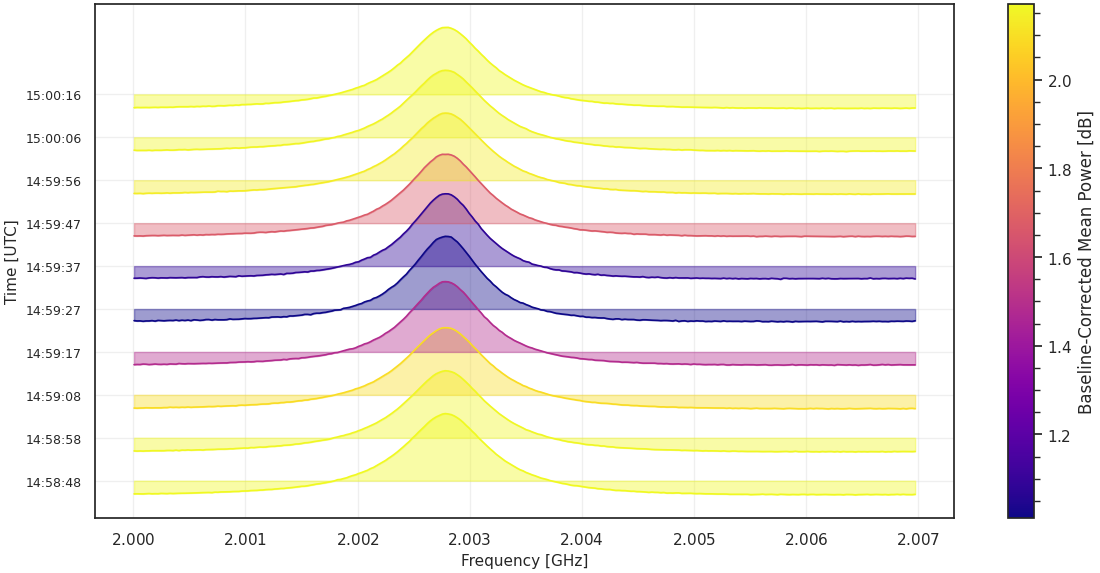

In [16]:
# plot the power spectrum
with h5py.File(filename,'r') as f:
    for g in groups:
        freq = f[f"{g}/frequency"][1600:-60] / 1e9     # convert to GHz
        spectrum = f[f"{g}/spectrum"][30:,1600:-60]    # (time × freq)
        time = f[f"{g}/timestamp"][30:,0]

        # build UTC time array
        time_utc = np.array([datetime.utcfromtimestamp(t) for t in time])

        n_samples = 10  # number of time segments
        n_time, n_freq = spectrum.shape

        # Split time indices into chunks
        time_chunks = np.array_split(np.arange(n_time), n_samples)

        mean_spectra = []
        det_power = []

        for index, chunk in enumerate(time_chunks):

            # average spectrum over the chunk
            mean_spectrum = 10 * np.log10(np.mean(spectrum[chunk, :]**2, axis=0))

            # baseline correction
            base_cor_spec = base_correction(freq, mean_spectrum)

            data_plot = base_cor_spec[mask] 
            det_power.append(data_plot)

        det_power = np.array(det_power)

# --- Normalize for color mapping ---
chunk_values = np.nanmean(det_power, axis=1)   # mean power per chunk
norm = plt.Normalize(vmin=np.min(chunk_values), vmax=np.max(chunk_values))
colors = cm.plasma(norm(chunk_values))

# --- Create Ridge Plot ---
fig, ax = plt.subplots(figsize=(12, 6))

for i, (spectrum_corr, color) in enumerate(zip(det_power, colors)):
    y_norm = (spectrum_corr - np.nanmean(spectrum_corr)) / np.nanstd(spectrum_corr)
    offset = i * 2.0
    ax.plot(freq[mask], y_norm + offset, color=color, lw=1.2)
    ax.fill_between(freq[mask], offset, y_norm + offset, color=color, alpha=0.4)

# --- Colorbar ---
sm = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=ax, label='Baseline-Corrected Mean Power [dB]')

time_numeric = np.array([t.timestamp() for t in time_utc])

import datetime

# average timestamp for each chunk
avg_times = [datetime.datetime.fromtimestamp(np.mean(time_numeric[c])) for c in time_chunks]

# make tick positions correspond to ridge offsets
tick_positions = np.arange(len(avg_times)) * 2.0
tick_labels = [t.strftime("%H:%M:%S") for t in avg_times]

ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)
# --- X-axis ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
#ax.set_title("Ridge Plot of Spectrum vs Frequency (Baseline-Corrected Averages)", fontsize=13)
ax.grid(alpha=0.3)


plt.tight_layout()
plt.show()


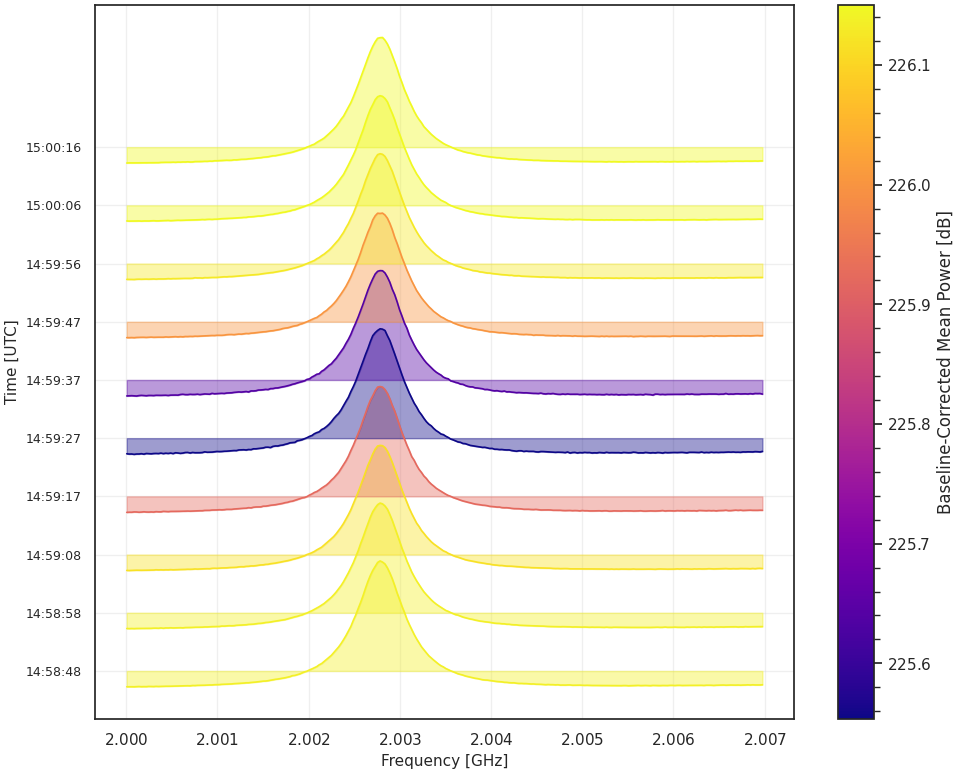

In [17]:
n_samples = 10  # number of time segments

# --- Split into equal time chunks ---
time_chunks = np.array_split(np.arange(n_time), n_samples)

# --- Compute averaged and baseline-corrected spectra ---
mean_spectra = []
det_power = []

for chunk in time_chunks:
    # Average over time within this chunk
    mean_spec = np.nanmean(spec[chunk, :], axis=0)
    
    # --- Baseline correction ---
    corrected_spec = base_correction(frequency, mean_spec)
    
    # Store corrected spectrum
    mean_spectra.append(corrected_spec)
    
    # Compute representative power (for color scaling)
    det_power.append(10 * np.log10(np.nanmean(corrected_spec**2)))

mean_spectra = np.array(mean_spectra)
det_power = np.array(det_power)

# --- Normalize for color mapping ---
norm = plt.Normalize(vmin=np.min(det_power), vmax=np.max(det_power))
colors = cm.plasma(norm(det_power))

# --- Create Ridge Plot ---
fig, ax = plt.subplots(figsize=(10, 8))

for i, (spectrum_corr, color) in enumerate(zip(mean_spectra, colors)):
    # Normalize each spectrum for shape comparison
    y_norm = (spectrum_corr - np.nanmean(spectrum_corr)) / np.nanstd(spectrum_corr)
    offset = i * 2.0  # vertical offset
    
    ax.plot(frequency, y_norm + offset, color=color, lw=1.2)
    ax.fill_between(frequency, offset, y_norm + offset, color=color, alpha=0.4)

# --- Colorbar ---
sm = cm.ScalarMappable(cmap=cm.plasma, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Baseline-Corrected Mean Power [dB]')

# --- FIXED Y-axis labels ---
import datetime
time_numeric = np.array([t.timestamp() for t in time_utc])

# average timestamp for each chunk
avg_times = [datetime.datetime.fromtimestamp(np.mean(time_numeric[c])) for c in time_chunks]

# make tick positions correspond to ridge offsets
tick_positions = np.arange(len(avg_times)) * 2.0
tick_labels = [t.strftime("%H:%M:%S") for t in avg_times]

ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)

# --- X-axis and aesthetics ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
#ax.set_title("Ridge Plot of Spectrum vs Frequency (Baseline-Corrected Averages)", fontsize=13)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [18]:


def plot_ridge_spectrum(time_utc, freq, spectrum, mask, n_samples=10, n_ticks=10):
    """
    Plot a ridge (joy) plot of spectra vs. frequency over time.

    Parameters
    ----------
    time_utc : array-like of datetime
        Array of UTC timestamps (same length as spectrum's first dimension).
    freq : array-like
        Frequency axis in GHz (same length as spectrum's second dimension).
    spectrum : 2D array (n_time, n_freq)
        Spectral power values (can be in linear or dB scale).
    mask : boolean array
        Frequency mask to select the frequency window of interest.
    n_samples : int, optional
        Number of time steps (ridges) to display. Default = 10.
    n_ticks : int, optional
        Number of y-axis time labels (UTC). Default = 10.
    """

    # --- 1 Apply mask to select frequency range ---
    frequency = freq[mask]
    spec = spectrum[:, mask]
    n_time, n_freq = spec.shape

    # --- 2 Select representative time samples for plotting ---
    idx = np.linspace(0, n_time - 1, n_samples, dtype=int)
    colors = cm.viridis(np.linspace(0, 1, n_samples))

    # --- 3 Create figure and axis ---
    fig, ax = plt.subplots(figsize=(10, 8))

    for i, (k, color) in enumerate(zip(idx, colors)):
        y = spec[k, :]

        # Normalize each spectrum so that differences in amplitude
        # don't dominate the plot (emphasizes shape instead of power).
        y_norm = (y - np.nanmean(y)) / np.nanstd(y)

        # Vertical offset for stacking ridges
        offset = i * 2.0

        # Plot line and fill below to create the "ridge" effect
        ax.plot(frequency, y_norm + offset, color=color, lw=1.2)
        ax.fill_between(frequency, offset, y_norm + offset, color=color, alpha=0.4)

    # --- 4 Y-axis: Label ridges with UTC time ---
    tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[idx[i]].strftime("%H:%M:%S") for i in tick_positions]

    ax.set_yticks(tick_positions * 2.0)  # Match vertical offset
    ax.set_yticklabels(tick_labels, fontsize=9)
    ax.set_ylabel("Time [UTC]", fontsize=11)

    # --- 5 X-axis and plot aesthetics ---
    ax.set_xlabel("Frequency [GHz]", fontsize=11)
    ax.set_title("Ridge Plot of Spectrum vs Frequency", fontsize=13)
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()


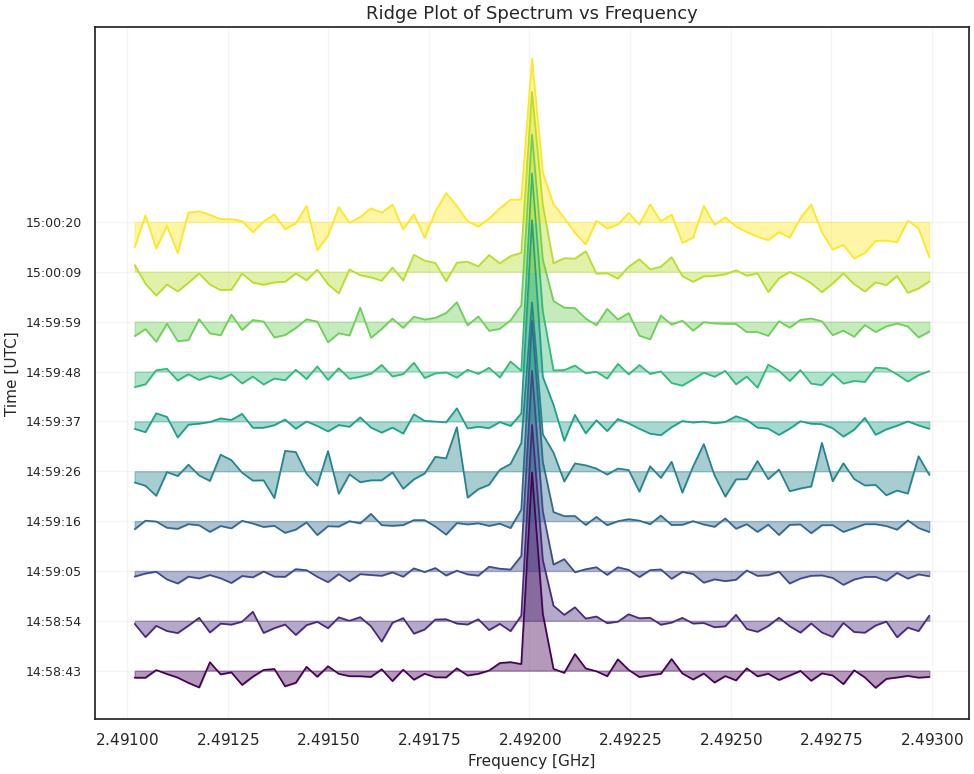

In [19]:
mask1 = (freq > 1.81) & (freq < 1.83) 
mask2 = (freq > 2.00) & (freq < 2.006) 
mask3 = (freq > 2.197) & (freq < 2.203) 
mask4 = (freq > 2.491) & (freq < 2.493) 

plot_ridge_spectrum(time_utc, freq, spectrum, mask4, n_samples=10, n_ticks=10)


In [20]:

# Ridge plot, to characterize the RFI

def ridgeplot_rfi_characterization(time_utc, frequency, spectrum, mask=None, n_samples=10, threshold=0.05, ax=None):
    """
    Create a ridge plot of spectra vs frequency and characterize RFI features
    at selected time steps.
    """
    # --- Apply mask if provided ---
    if mask is not None:
        freq = frequency[mask]
        spec = spectrum[:, mask]
    else:
        freq = frequency
        spec = spectrum

    n_time = spec.shape[0]
    idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

    # Compute mean power per spectrum for colormap
    mean_power = [10 * np.log10(np.nanmean(spec[k, :]**2)) for k in idx]
    norm = plt.Normalize(min(mean_power), max(mean_power))
    colors = cm.plasma(norm(mean_power))

    # --- Create Figure ---
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))

    print("\n === RFI CHARACTERIZATION PER TIME STEP ===")
    print(f"Using threshold: {threshold:.3f}\n")

    for i, (k, color) in enumerate(zip(idx, colors)):
        y = spec[k, :]
        y_db = 10 * np.log10(y**2)  # Convert to dB, avoid log(0)
        y_norm = (y_db - np.nanmean(y_db)) / np.nanstd(y_db)
        offset = i * 2.0

        # --- Plot ridge ---
        ax.plot(freq, y_norm + offset, color=color, lw=1.2)
        ax.fill_between(freq, offset, y_norm + offset, color=color, alpha=0.4)

        # --- RFI characterization ---
        above_threshold = np.where(y_db > threshold)[0]
        if len(above_threshold) > 0:
            start_index, end_index = above_threshold[0], above_threshold[-1]
            start_freq = freq[start_index]
            end_freq = freq[end_index]
            peak_index = np.argmax(y_db)
            peak_freq = freq[peak_index]
            peak_power = y_db[peak_index]

            delta_f = np.mean(np.diff(freq))  # channel width
            n_channels = (end_freq - start_freq) / delta_f
            bandwidth = (end_freq - start_freq) * 1e3  # GHz → MHz

            print(f"[{time_utc[k].strftime('%H:%M:%S')}]  "
                  f"Peak: {peak_freq:.6f} GHz | Power: {peak_power:.3f} dB | "
                  f"BW: {bandwidth:.2f} MHz | Channels: {n_channels:.1f}")
        else:
            print(f"[{time_utc[k].strftime('%H:%M:%S')}]  No RFI detected above threshold.")

    # colorbar to interoret variation
    sm=cm.ScalarMappable(cmap=cm.plasma, norm=norm)
    sm.set_array([])
    cbar=plt.colorbar(sm,ax=ax, label='Mean Power [dB]')

    # --- Y-axis: Time Labels (UTC) ---
    n_ticks = min(10, n_samples)
    tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
    tick_labels = [time_utc[idx[i]].strftime("%H:%M:%S") for i in tick_positions]

    ax.set_yticks(tick_positions * 2.0)
    ax.set_yticklabels(tick_labels, fontsize=12)
    ax.set_ylabel("Time [UTC]", fontsize=16)

    # --- X-axis ---
    ax.set_xlabel("Frequency [GHz]", fontsize=16)
    ax.set_title("RFI variation over the Observation", fontsize=13)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()



 === RFI CHARACTERIZATION PER TIME STEP ===
Using threshold: 0.050

[14:58:43]  Peak: 2.002810 GHz | Power: 240.193 dB | BW: 6.97 MHz | Channels: 261.0
[14:58:54]  Peak: 2.002756 GHz | Power: 240.347 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:05]  Peak: 2.002810 GHz | Power: 240.107 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:16]  Peak: 2.002810 GHz | Power: 240.689 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:26]  Peak: 2.002783 GHz | Power: 242.194 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:37]  Peak: 2.002756 GHz | Power: 241.946 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:48]  Peak: 2.002836 GHz | Power: 240.675 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:59]  Peak: 2.002836 GHz | Power: 240.415 dB | BW: 6.97 MHz | Channels: 261.0
[15:00:09]  Peak: 2.002810 GHz | Power: 240.364 dB | BW: 6.97 MHz | Channels: 261.0
[15:00:20]  Peak: 2.002810 GHz | Power: 240.325 dB | BW: 6.97 MHz | Channels: 261.0


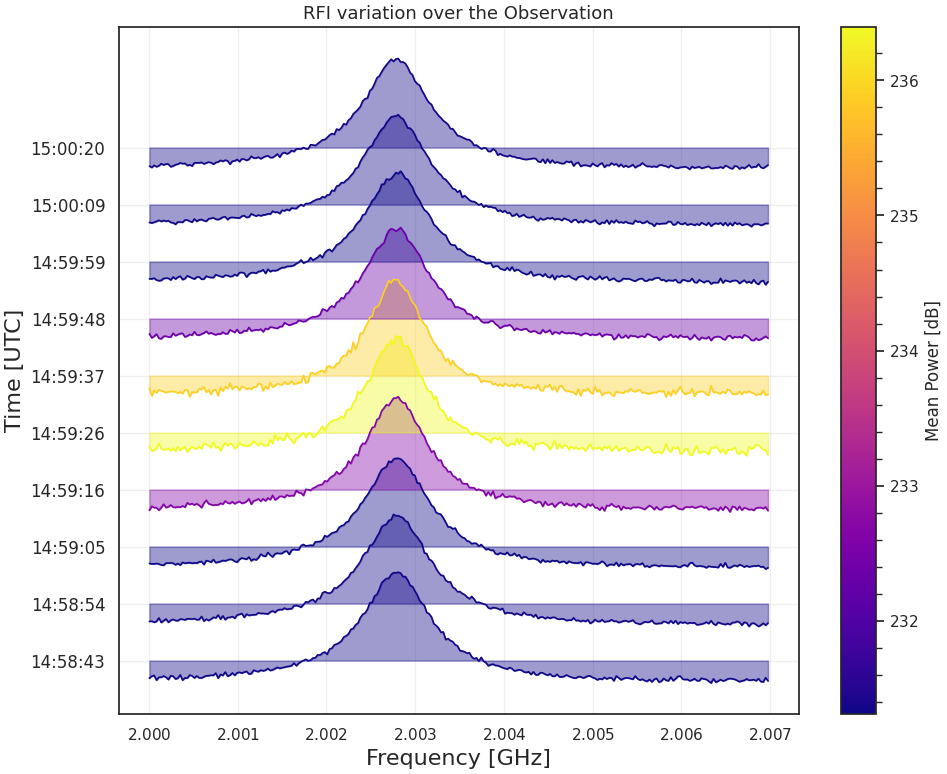

In [21]:
ridgeplot_rfi_characterization(time_utc, freq, spectrum, mask=mask, n_samples=10, threshold=0.05)


Start Frequency  : 2.000326 GHz
End Frequency    : 2.004839 GHz
Peak Frequency   : 2.002783 GHz  | Power = 10.165 dB
Corrupted Channels: 169.0
Corrupted Bandwidth         : 4.51 MHz
Gaussian FWHM    : 995.85 kHz
Number of Channels at FWHM: 38.0


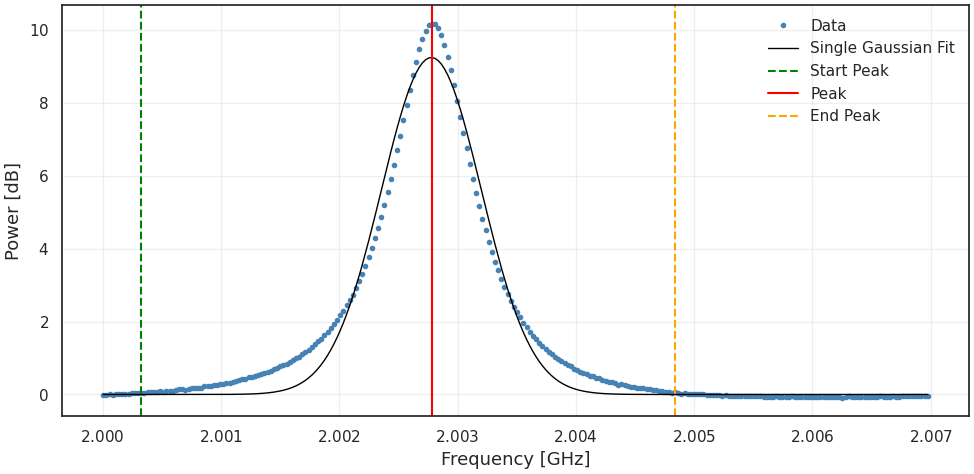

In [22]:
results = characterize_RFI_width(freq[mask], power_base_core[mask], tie=False,)


Start Frequency  : 2.000326 GHz
End Frequency    : 2.004839 GHz
Peak Frequency   : 2.002783 GHz  | Power = 10.165 dB
Corrupted Channels: 169.0
Corrupted Bandwidth         : 4.51 MHz
Gaussian FWHM    : 995.85 kHz
Number of Channels at FWHM: 38.0



 === RFI CHARACTERIZATION PER TIME STEP ===
Using threshold: 0.050

[14:58:43]  Peak: 2.002810 GHz | Power: 240.193 dB | BW: 6.97 MHz | Channels: 261.0
[14:58:54]  Peak: 2.002756 GHz | Power: 240.347 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:05]  Peak: 2.002810 GHz | Power: 240.107 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:16]  Peak: 2.002810 GHz | Power: 240.689 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:26]  Peak: 2.002783 GHz | Power: 242.194 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:37]  Peak: 2.002756 GHz | Power: 241.946 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:48]  Peak: 2.002836 GHz | Power: 240.675 dB | BW: 6.97 MHz | Channels: 261.0
[14:59:59]  Peak: 2.002836 GHz | Power: 240.415 dB | BW: 6.97 MHz | Channels: 261.0
[15:00:09]  Peak: 2.002810 GHz | Power: 240.364 dB | BW: 6.97 MHz | Channels: 261.0
[15:00:20]  Peak: 2.002810 GHz | Power: 240.325 dB | BW: 6.97 MHz | Channels: 261.0


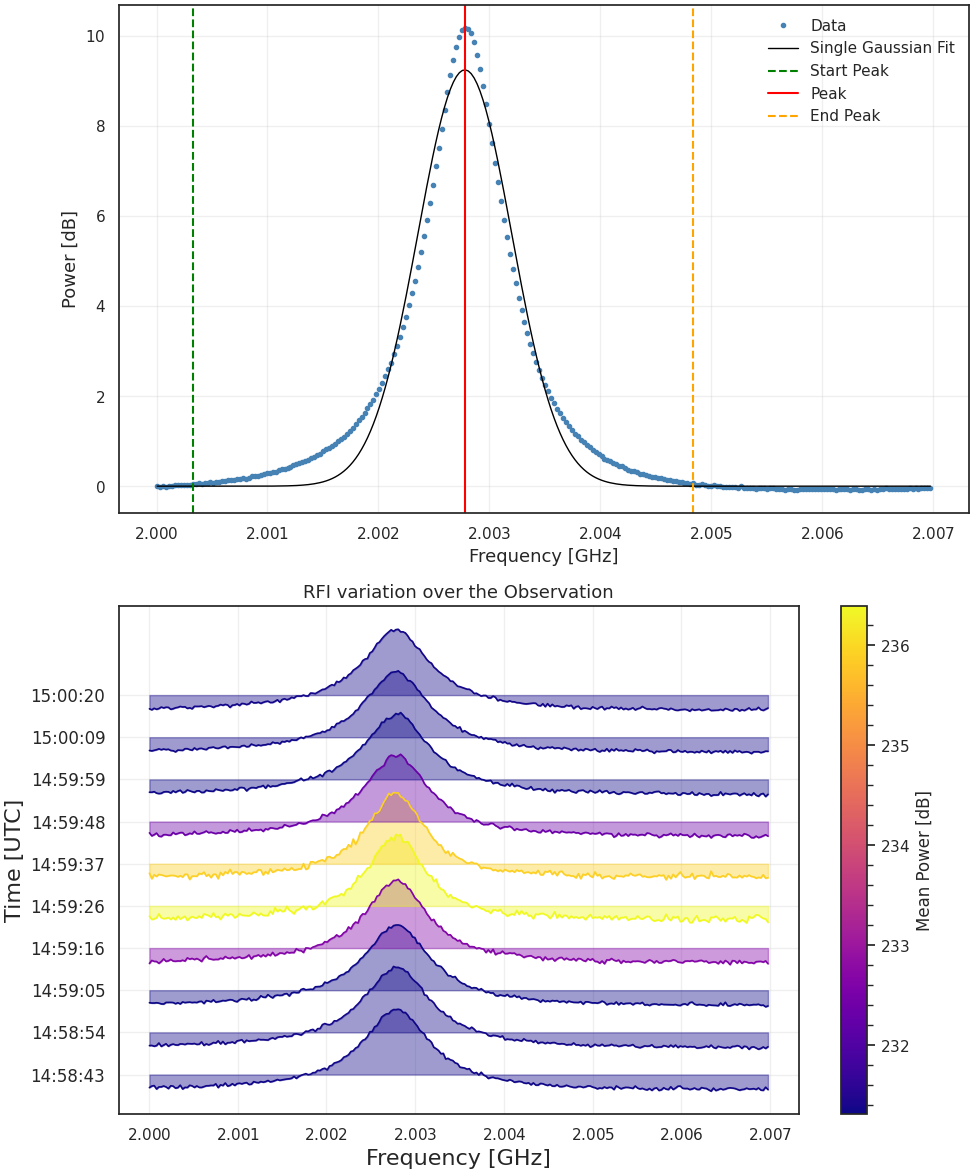

In [23]:
fig, ax=plt.subplots(2,1, figsize=(10,12))
plt.subplots_adjust(hspace=0.5)

results = characterize_RFI_width(freq[mask], power_base_core[mask], tie=False, ax=ax[0])
ridgeplot_rfi_characterization(time_utc, freq, spectrum, mask=mask, n_samples=10, threshold=0.05, ax=ax[1])


In [24]:
# a =np.sin(t)
# b = 10*a

# det_a 
# det_b
# c = np.random*a
# det_a
# det_c

In [25]:
n_samples = 10000
# create time axis: over 10 min with n_samples time steps
t = np.linspace(12, 50, n_samples)
x = np.random.normal(12, 50, n_samples)


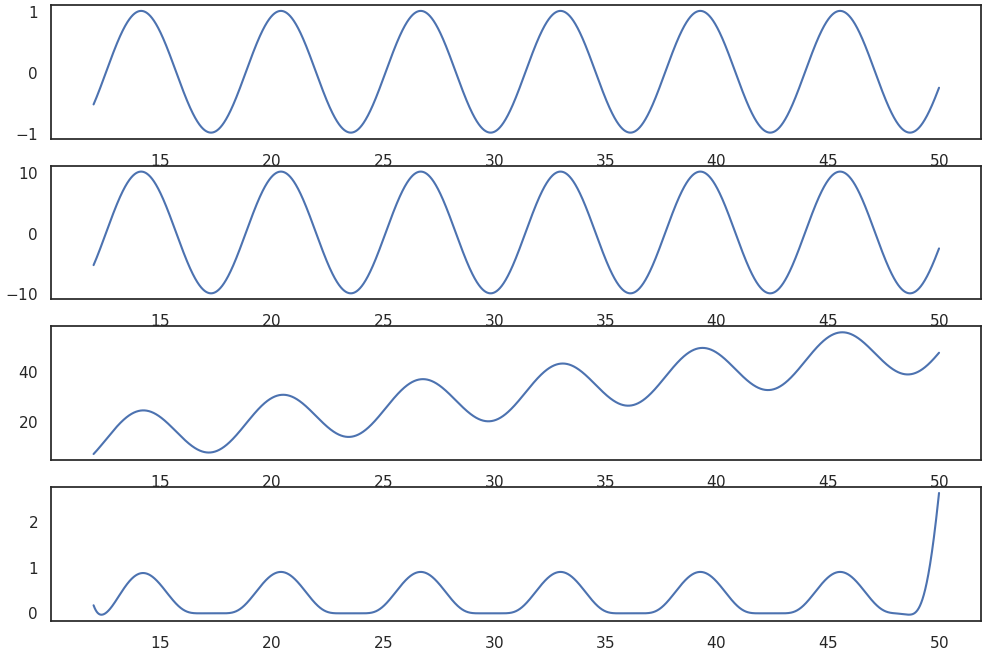

In [26]:

# simulate a SIN function
y = np.sin(t)
f = 10*y
h = f + t

# detrend the function h

det = base_correction(t, h)


fig, ax = plt.subplots(4,1, figsize=(12,8))


ax[0].plot(t,y)

ax[1].plot(t,f)

ax[2].plot(t,h)

ax[3].plot(t, det)





In [27]:
df = pd.read_csv('/home/chavango/Master/Simulated-Data/Simulation_of_receiver_output-interferometer.csv')
df.head()

,Time,Detected_Signal,Clean_Astronomical_Signal,Astronomical_Signal
0,0.0000,4.299818,4.299818,0.000000
1,0.0005,10.367376,3.481124,0.078217
2,0.0010,8.199533,5.795392,0.154508
3,0.0015,5.898824,4.609676,0.226995
4,0.0020,3.785286,5.773155,0.293893


In [28]:
df.columns

Index(['Time', 'Detected_Signal', 'Clean_Astronomical_Signal',
       'Astronomical_Signal'],
      dtype='object')

In [29]:

# define variables
fs = 2000 # samplig frequency in Hz
time = df['Time']
s_rfi = df['Detected_Signal'] # signal detected by receiver
s_wrfi = df['Clean_Astronomical_Signal'] # astronomical signal (+ noise)
sig = df['Astronomical_Signal'] # source signal


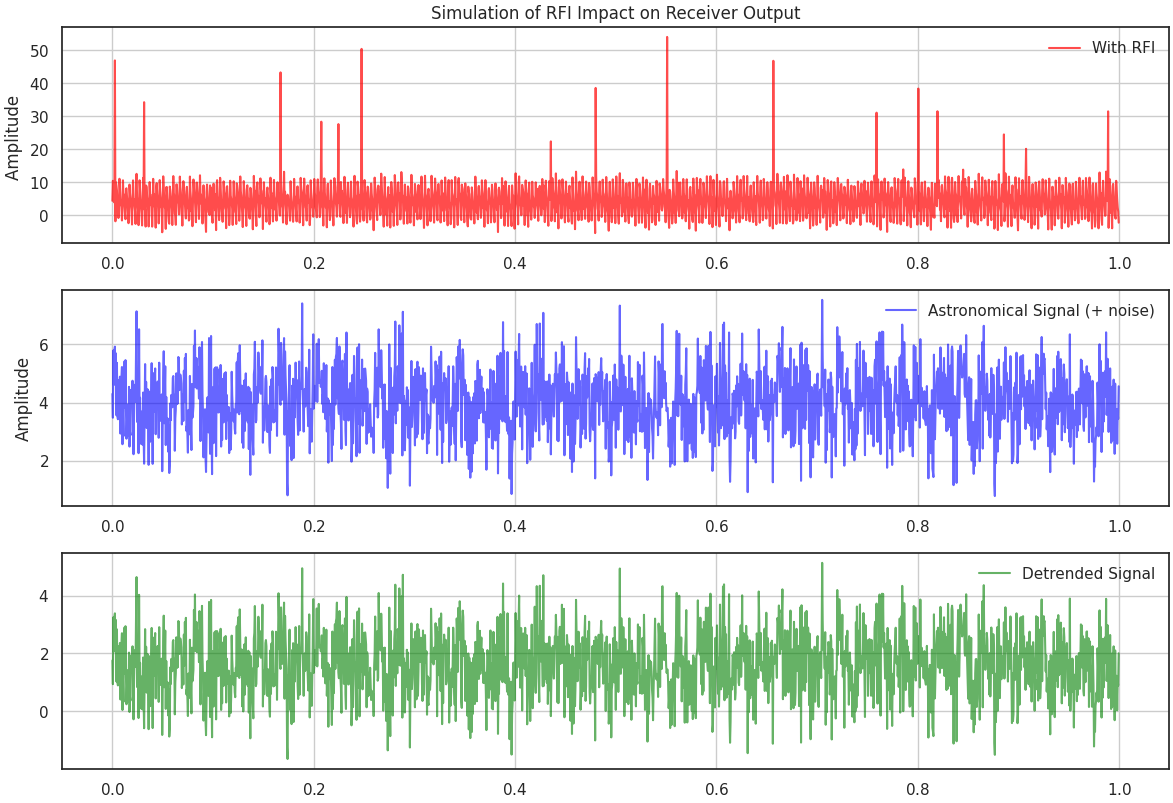

In [30]:

det = base_correction(time,s_rfi)
det_x = base_correction(time, s_wrfi)


plt.figure(figsize=(12,8))

plt.subplot(3,1,1)
plt.plot(time, s_rfi, label='With RFI', color='red', alpha=0.7)
plt.title("Simulation of RFI Impact on Receiver Output")
plt.ylabel("Amplitude ")
plt.legend()
plt.grid(True)
plt.tight_layout()


plt.subplot(3,1,2)
plt.plot(time, s_wrfi, label='Astronomical Signal (+ noise)', color='blue', alpha=0.6)
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.subplot(3,1,3)
plt.plot(time, det_x, label='Detrended Signal', color='green', alpha=0.6)
plt.grid()
plt.legend()



In [31]:
n_time, n_freq = spectrum.shape

# --- Configuration ---
n_samples = 10                         # number of ridges to show
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)  # indices of the selected times

# One color per ridge using the mean power at that time index
mean_power = np.nanmean(spectrum[idx, :], axis=1)

In [32]:
freq.shape

(63877,)

In [33]:
# Step 1: define the baseli fitting
baseline_fitter = Baseline(x_data=freq[idx])
bkg, params = baseline_fitter.asls(mean_power, lam=1e7, p=0.02)

# Step 2: Substract the baseline
correct_baseline = mean_power - bkg


correct_baseline.shape

(10,)

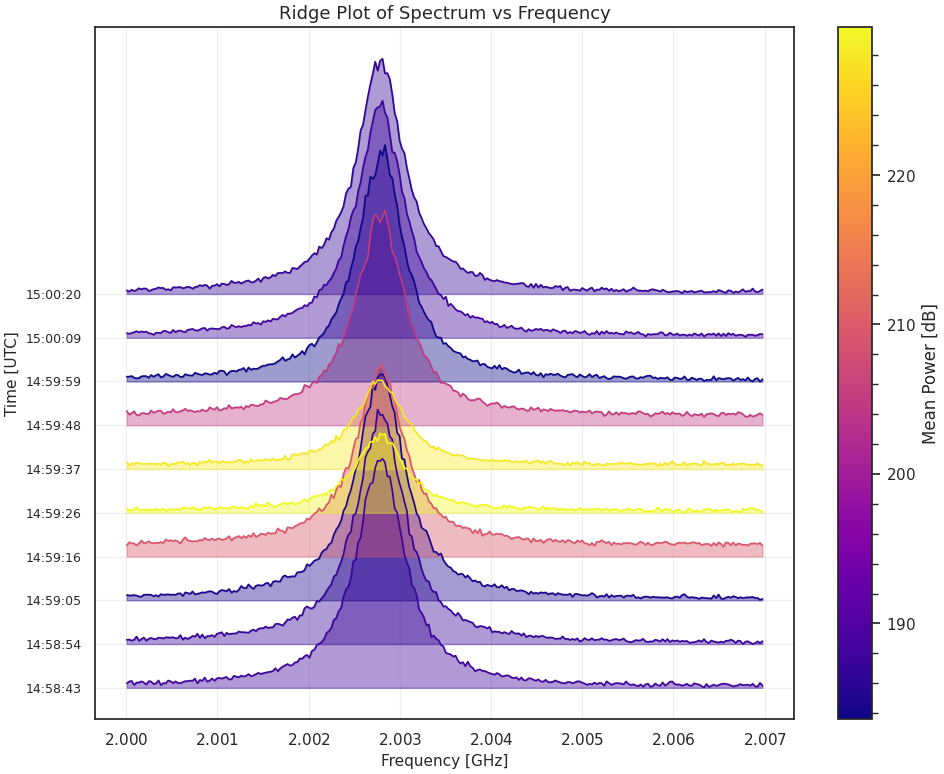

In [34]:
n_time, n_freq = spectrum.shape

# --- Configuration ---
n_samples = 10                         # number of ridges to show
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)  # indices of the selected times


# One color per ridge using the mean power at that time index
mean_power = np.nanmean(spectrum[idx, :], axis=1)


# Step 1: define the baseli fitting
baseline_fitter = Baseline(x_data=freq[idx])
bkg, params = baseline_fitter.asls(mean_power, lam=1e7, p=0.02)

# Step 2: Substract the baseline
correct_baseline = 10 * np.log10((mean_power - bkg)**2)

# --- Normalize color map across the full dynamic range ---
norm = plt.Normalize(vmin=np.nanmin(correct_baseline), vmax=np.nanmax(correct_baseline))
cmap = cm.plasma

colors = cmap(norm(correct_baseline))

# --- Create figure ---
fig, ax = plt.subplots(figsize=(10, 8))

for k, (i, color) in enumerate(zip(idx, colors)):
    y = spectrum[i]

    # Normalize each spectrum for ridge visualization
    y_norm = (y - np.nanmean(y)) / np.nanstd(y)

    # Vertical offset per ridge
    offset = k * 2.0

    # Plot ridge
    ax.plot(freq[mask], y_norm[mask] + offset, color=color, lw=1.2)
    ax.fill_between(freq[mask], offset, y_norm[mask] + offset, color=color, alpha=0.4)

# --- Colorbar ---
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Mean Power [dB]')

# --- Y-axis time ticks ---
n_ticks = min(10, n_samples)
tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
tick_labels = [time_utc[idx[p]].strftime("%H:%M:%S") for p in tick_positions]

ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)

# --- X-axis and decorations ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
ax.set_title("Ridge Plot of Spectrum vs Frequency", fontsize=13)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [35]:
10 * np.log10((mean_power - bkg)**2)

array([188.05925, 186.88652, 184.37181, 209.2871 , 229.88089, 228.24174,
       204.9344 , 183.5897 , 188.02176, 186.7232 ], dtype=float32)

In [36]:

# Example: spectrum.shape = (634, 63877)
n_time, n_freq = spectrum.shape
n_samples = 10

# Number of time points per chunk
chunk_size = n_time // n_samples  # 634 // 10 = 63
remainder = n_time % n_samples   # 634 % 10 = 4

averaged_spectra = []

start_idx = 0
for i in range(n_samples):
    # Handle remainder by adding one extra sample to the first 'remainder' chunks
    end_idx = start_idx + chunk_size + (1 if i < remainder else 0)
    
    chunk = spectrum[start_idx:end_idx, :]  # shape ~ (63, 63877)
    avg_chunk = chunk.mean(axis=0)          # average over time → shape (63877,)
    averaged_spectra.append(avg_chunk)
    
    start_idx = end_idx

# Convert list to array: shape (10, 63877)
averaged_spectra = np.array(averaged_spectra)
print(averaged_spectra.shape)


(10, 63877)


In [37]:

# Example: spectrum.shape = (634, 63877)
n_time, n_freq = spectrum.shape
n_samples = 10

# Number of time points per chunk
chunk_size = n_time // n_samples  # 634 // 10 = 63
remainder = n_time % n_samples   # 634 % 10 = 4

averaged_spectra = []

start_idx = 0
for i in range(n_samples):
    # Handle remainder by adding one extra sample to the first 'remainder' chunks
    end_idx = start_idx + chunk_size + (1 if i < remainder else 0)
    
    chunk = spectrum[start_idx:end_idx, :]  # shape ~ (63, 63877)
    avg_chunk = chunk.mean(axis=0)          # average over time → shape (63877,)
    averaged_spectra.append(avg_chunk)
    
    start_idx = end_idx

# Convert list to array: shape (10, 63877)
averaged_spectra = np.array(averaged_spectra)


colors = cmap(norm(averaged_spectra))

# # --- Create figure ---
# fig, ax = plt.subplots(figsize=(10, 8))

# for k, (i, color) in enumerate(zip(idx, colors)):
#     y = spectrum[i]

#     # Normalize each spectrum for ridge visualization
#     y_norm = (y - np.nanmean(y)) / np.nanstd(y)

#     # Vertical offset per ridge
#     offset = k * 2.0

#     # Plot ridge
#     ax.plot(freq, y_norm + offset, color=color, lw=1.2)
#     ax.fill_between(freq, offset, y_norm + offset, color=color, alpha=0.4)

# # --- Colorbar ---
# sm = cm.ScalarMappable(cmap=cmap, norm=norm)
# sm.set_array([])
# cbar = plt.colorbar(sm, ax=ax, label='Mean Power [dB]')

# # --- Y-axis time ticks ---
# n_ticks = min(10, n_samples)
# tick_positions = np.linspace(0, n_samples - 1, n_ticks, dtype=int)
# tick_labels = [time_utc[idx[p]].strftime("%H:%M:%S") for p in tick_positions]

# ax.set_yticks(tick_positions * 2.0)
# ax.set_yticklabels(tick_labels, fontsize=9)
# ax.set_ylabel("Time [UTC]", fontsize=11)

# # --- X-axis and decorations ---
# ax.set_xlabel("Frequency [GHz]", fontsize=11)
# ax.set_title("Ridge Plot of Spectrum vs Frequency", fontsize=13)
# ax.grid(alpha=0.3)

# plt.tight_layout()
# plt.show()
# 3

In [38]:
averaged_spectra

array([[1.8709080e+11, 1.8831519e+11, 1.8705575e+11, ..., 4.1166661e+09,
        4.1145326e+09, 4.1120223e+09],
       [1.8843438e+11, 1.8761169e+11, 1.8828732e+11, ..., 4.1206356e+09,
        4.1185267e+09, 4.1049864e+09],
       [1.9878901e+11, 1.9879295e+11, 1.9846577e+11, ..., 4.1440397e+09,
        4.1606799e+09, 4.1365673e+09],
       ...,
       [1.9304682e+11, 1.9313479e+11, 1.9299390e+11, ..., 4.1395589e+09,
        4.1490975e+09, 4.1324339e+09],
       [1.8857691e+11, 1.8824323e+11, 1.8743407e+11, ..., 4.1084895e+09,
        4.1471962e+09, 4.1112791e+09],
       [1.8843787e+11, 1.8821625e+11, 1.8803275e+11, ..., 4.1090337e+09,
        4.1024256e+09, 4.1350646e+09]], dtype=float32)

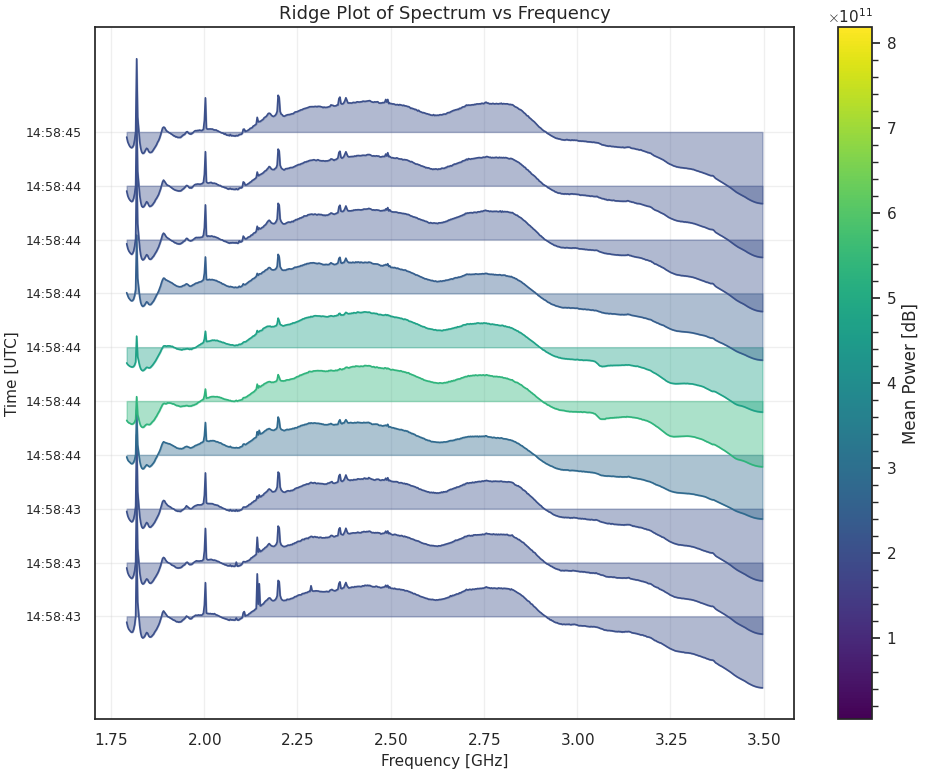

In [39]:

# Optional: downsample frequency for plotting
factor = 100
freq_ds = freq[::factor]
averaged_spectra_ds = averaged_spectra[:, ::factor]

# Normalize for color mapping
norm = plt.Normalize(averaged_spectra_ds.min(), averaged_spectra_ds.max())
cmap = cm.viridis
colors = [cmap(norm(avg)) for avg in averaged_spectra_ds]

# --- Create figure ---
fig, ax = plt.subplots(figsize=(10, 8))
y_offsets = np.arange(averaged_spectra_ds.shape[0]) * 2.0  # vertical offsets

for k, (avg_spectrum, y_offset) in enumerate(zip(averaged_spectra_ds, y_offsets)):
    # Normalize each spectrum for ridge visualization
    y_norm = (avg_spectrum - np.nanmean(avg_spectrum)) / np.nanstd(avg_spectrum)
    color = cmap(norm(avg_spectrum.mean()))  # color based on mean intensity

    # Plot ridge
    ax.plot(freq_ds, y_norm + y_offset, color=color, lw=1.2)
    ax.fill_between(freq_ds, y_offset, y_norm + y_offset, color=color, alpha=0.4)

    
# --- Colorbar ---
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Mean Power [dB]')

# --- Y-axis time ticks ---
n_ticks = min(10, averaged_spectra_ds.shape[0])
tick_positions = np.linspace(0, averaged_spectra_ds.shape[0] - 1, n_ticks, dtype=int)
tick_labels = [time_utc[pos].strftime("%H:%M:%S") for pos in tick_positions]
ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)

# --- X-axis and decorations ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
ax.set_title("Ridge Plot of Spectrum vs Frequency", fontsize=13)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


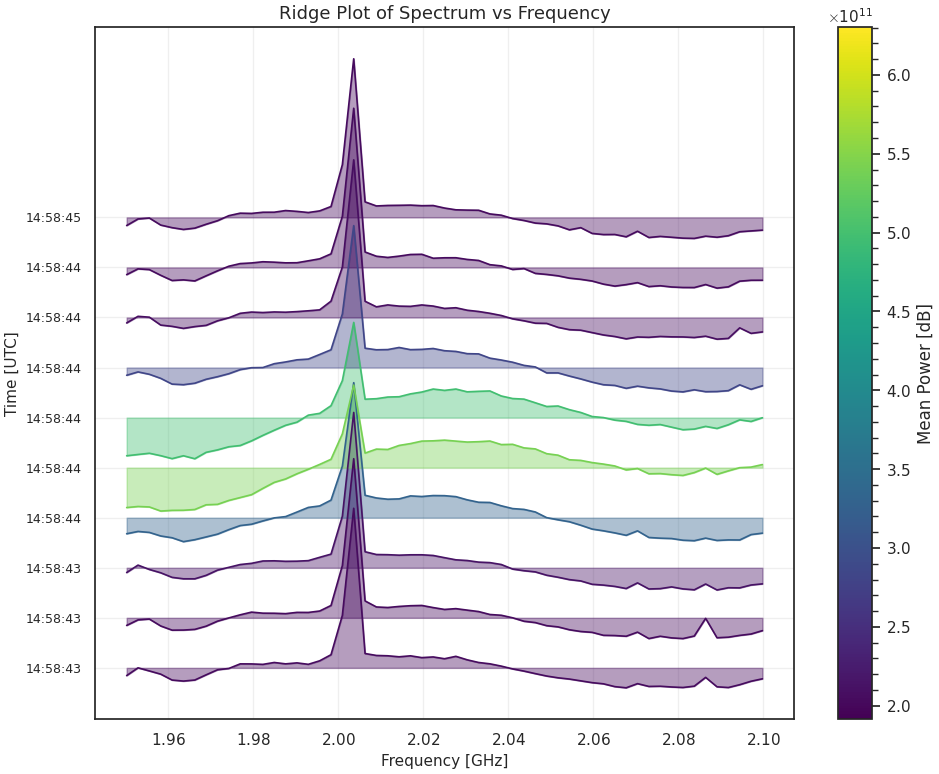

In [40]:

# Optional: downsample frequency for plotting
factor = 100
freq_ds = freq[::factor]
averaged_spectra_ds = averaged_spectra[:, ::factor]

# --- Apply mask AFTER downsampling ---
mask = (freq_ds > 1.95) & (freq_ds < 2.1)

freq_ds = freq_ds[mask]
averaged_spectra_ds = averaged_spectra_ds[:, mask]

# Normalize for color mapping
norm = plt.Normalize(averaged_spectra_ds.min(), averaged_spectra_ds.max())
cmap = cm.viridis
colors = [cmap(norm(avg)) for avg in averaged_spectra_ds]

# --- Create figure ---
fig, ax = plt.subplots(figsize=(10, 8))
y_offsets = np.arange(averaged_spectra_ds.shape[0]) * 2.0  # vertical offsets

for k, (avg_spectrum, y_offset) in enumerate(zip(averaged_spectra_ds, y_offsets)):
    # Normalize each spectrum for ridge visualization
    y_norm = (avg_spectrum - np.nanmean(avg_spectrum)) / np.nanstd(avg_spectrum)
    color = cmap(norm(avg_spectrum.mean()))  # color based on mean intensity

    # Plot ridge
    ax.plot(freq_ds, y_norm + y_offset, color=color, lw=1.2)
    ax.fill_between(freq_ds, y_offset, y_norm + y_offset, color=color, alpha=0.4)

    
# --- Colorbar ---
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Mean Power [dB]')

# --- Y-axis time ticks ---
n_ticks = min(10, averaged_spectra_ds.shape[0])
tick_positions = np.linspace(0, averaged_spectra_ds.shape[0] - 1, n_ticks, dtype=int)
tick_labels = [time_utc[pos].strftime("%H:%M:%S") for pos in tick_positions]
ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)

# --- X-axis and decorations ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
ax.set_title("Ridge Plot of Spectrum vs Frequency", fontsize=13)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [41]:
# weighted average:

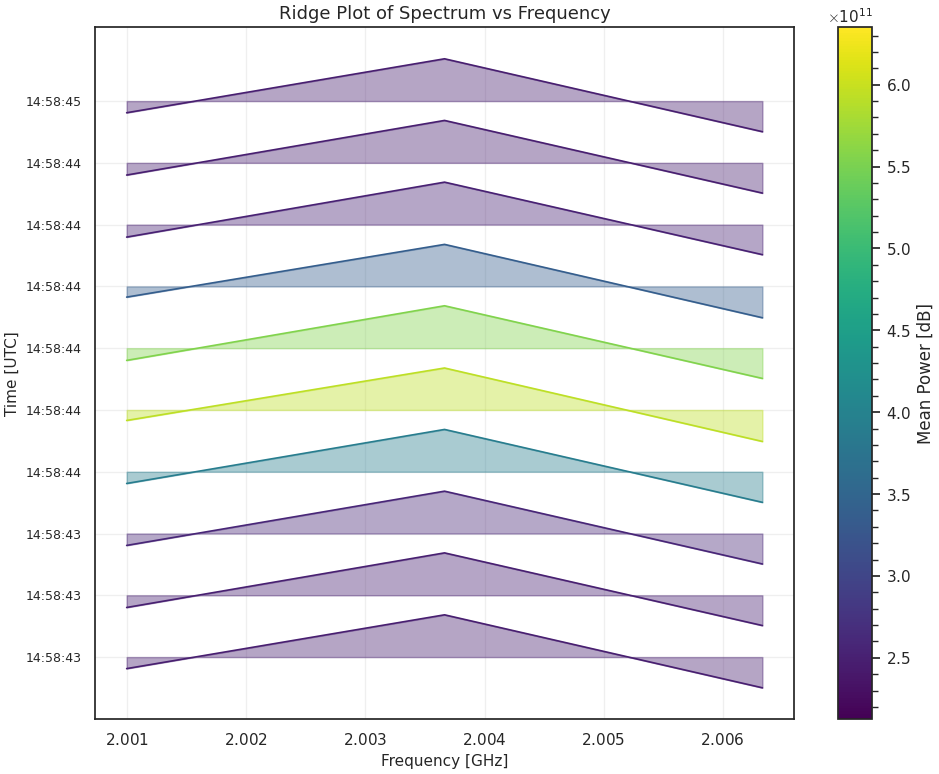

In [42]:
# Weight of each time slice = mean signal power
weights = np.nanmean(spectrum, axis=1)

averaged_spectra = []
start_idx = 0

for i in range(n_samples):

    end_idx = start_idx + chunk_size + (1 if i < remainder else 0)

    chunk = spectrum[start_idx:end_idx, :]
    w = weights[start_idx:end_idx]

    avg_chunk = np.average(chunk, axis=0, weights=w)
    averaged_spectra.append(avg_chunk)

    start_idx = end_idx

# Convert list → ndarray   shape = (n_samples, n_freq)
averaged_spectra = np.array(averaged_spectra)

# Downsample
factor = 100
freq_ds = freq[::factor]
averaged_spectra_ds = averaged_spectra[:, ::factor]

# Build mask on the DOWNSAMPLED freq
mask = (freq_ds > 2.00) & (freq_ds < 2.007)

# Apply mask
freq_ds = freq_ds[mask]
averaged_spectra_ds = averaged_spectra_ds[:, mask]


# Normalize for color mapping
norm = plt.Normalize(averaged_spectra_ds.min(), averaged_spectra_ds.max())
cmap = cm.viridis
colors = [cmap(norm(avg)) for avg in averaged_spectra_ds]

# --- Create figure ---
fig, ax = plt.subplots(figsize=(10, 8))
y_offsets = np.arange(averaged_spectra_ds.shape[0]) * 2.0  # vertical offsets

for k, (avg_spectrum, y_offset) in enumerate(zip(averaged_spectra_ds, y_offsets)):
    # Normalize each spectrum for ridge visualization
    y_norm = (avg_spectrum - np.nanmean(avg_spectrum)) / np.nanstd(avg_spectrum)
    color = cmap(norm(avg_spectrum.mean()))  # color based on mean intensity

    # Plot ridge
    ax.plot(freq_ds, y_norm + y_offset, color=color, lw=1.2)
    ax.fill_between(freq_ds, y_offset, y_norm + y_offset, color=color, alpha=0.4)

    
# --- Colorbar ---
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Mean Power [dB]')

# --- Y-axis time ticks ---
n_ticks = min(10, averaged_spectra_ds.shape[0])
tick_positions = np.linspace(0, averaged_spectra_ds.shape[0] - 1, n_ticks, dtype=int)
tick_labels = [time_utc[pos].strftime("%H:%M:%S") for pos in tick_positions]
ax.set_yticks(tick_positions * 2.0)
ax.set_yticklabels(tick_labels, fontsize=9)
ax.set_ylabel("Time [UTC]", fontsize=11)

# --- X-axis and decorations ---
ax.set_xlabel("Frequency [GHz]", fontsize=11)
ax.set_title("Ridge Plot of Spectrum vs Frequency", fontsize=13)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
